# De los resultados de las pruebas a clases de riesgo, plazos, opiniones y apetito

**Pregunta:** ¿Cómo se convierten los resultados de las pruebas de validación en un nivel para cada modelo, un plazo para cada hallazgo, una opinión sobre cada modelo y una luz para todo el inventario, y cuáles de esos veredictos descansan en una convención y no en la evidencia?

- **Nivel:** 2, El método en la práctica
- **Requisitos previos:** los notebooks 01 a 03 de este tema (el tamaño y la potencia de las pruebas cuyos resultados se gobiernan)
- **Tiempo de lectura:** unos 50 minutos

## Objetivos

Al terminar este notebook puedes:

- leer los seis documentos de gobierno del producto y decir qué guarda cada uno, desde el registro de modelos del caso C22 hasta las métricas de apetito;
- recalcular con el motor el nivel de cada entrada del inventario a partir de sus puntajes y ubicarlo en la matriz de 4 por 4;
- decir cuántos modelos cambian de nivel cuando la rúbrica se lee de otra de sus cuatro maneras y cómo depende el conteo de niveles de los cortes de la banda de exposición;
- recalcular el plazo y la fecha de vencimiento de cada hallazgo del registro y la opinión que recibe cada modelo según sus hallazgos abiertos;
- recalcular las siete métricas de apetito y las luces de referencia del contrato del motor, y correr toda la cadena sobre un modelo propio.

## Preparación

Instala una vez el entorno fijado, en un entorno virtual, con el comando de siempre:

```bash
pip install -r notebooks/requirements.txt
```

o solo los paquetes que usa este notebook, con las mismas versiones exactas:

```bash
pip install riskvalidation==1.1.0 numpy==2.4.6 matplotlib==3.11.2
```

`scripts/setup.sh --notebooks` (`scripts/setup.ps1 -Notebooks` en Windows) construye `.venv-notebooks` por ti. La celda siguiente importa los paquetes e imprime sus versiones.

In [1]:
# Importar las herramientas e imprimir las versiones con que corren
import importlib.metadata as md
import json
from collections import Counter
from datetime import date
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import riskvalidation as rv

for name in ("riskvalidation", "numpy", "matplotlib"):
    print(name, md.version(name))

riskvalidation 1.1.0
numpy 2.4.6
matplotlib 3.11.2


## Datos

Los datos son los documentos que la capa de gobierno del producto escribe a partir de los resultados de cada caso, leídos de `data/derived/` y de los fixtures de los contratos; no se lee ningún dato crudo. Todos los genera el producto con sus propios resultados confirmados (clase de licencia `generated`).

- **Registro de modelos de C22** (`data/derived/C22/models-generators.json`, contrato `c22-models`): `model`, `fit` con sus `studies` (los estudios nombrados de tamaño y potencia, con sus argumentos fijos, repeticiones y semillas) y sus filas de `parity`, `provenance` y `lane`.
- **Inventario** (`governance/inventory.json`, contrato `governance-inventory`): `entries`, una por modelo, cada una con 40 `attributes` que llevan un `value`, un `status` y un `basis`, un `tier_block`, un `lifecycle`, un `schedule` y un `scope`; las `edges` entre entradas; `completeness`, `tier_counts` y los `governance_findings` propios del inventario.
- **Registro de hallazgos** (`governance/findings.json`, contrato `governance-findings`): `rows`, cada una un hallazgo de una variante con su `severity`, `status`, `tier`, `raised`, `deadline_days`, `due`, `overdue` y `rwea_share`, y las `conventions` que los fijaron.
- **Informe** (`governance/reports/C22-generators.json`, contrato `governance-report`): las doce `sections` del informe de validación de una entrada.
- **Apetito** (`governance/appetite.json`, contrato `governance-appetite`): siete `metrics`, cada una con su `value`, `numerator`, `denominator` y `light`.
- **Fixture** (`docs/contracts/fixtures/governance/inventory-fixture.json`): el inventario de cuatro entradas sobre el que el contrato del motor declara sus valores de referencia (`engine-governance-api`).

La celda siguiente los carga e imprime sus tamaños.

In [2]:
# Cargar los seis documentos de gobierno e imprimir lo que guarda cada uno
LANG = "es"
ROOT = Path("../../..").resolve()
GOV = ROOT / "data" / "derived" / "governance"
read = lambda path: json.loads(path.read_text(encoding="utf-8"))
models = read(ROOT / "data" / "derived" / "C22" / "models-generators.json")
inventory, findings, appetite = (read(GOV / f"{name}.json") for name in ("inventory", "findings", "appetite"))
report = read(GOV / "reports" / "C22-generators.json")
fixture = read(ROOT / "docs" / "contracts" / "fixtures" / "governance" / "inventory-fixture.json")
entries, rows = inventory["entries"], findings["rows"]
print("entradas del inventario:", len(entries), "| filas del registro:", len(rows), "| a la fecha:", findings["as_of"])
print("estudios de tamaño y potencia de C22:", len(models["fit"]["studies"]))
print("filas de paridad:", len(models["fit"]["parity"]))
print("informe de:", report["entry_key"], "| secciones:", len(report["sections"]))

entradas del inventario: 34 | filas del registro: 745 | a la fecha: 2026-11-08
estudios de tamaño y potencia de C22: 25
filas de paridad: 564
informe de: C22/generators | secciones: 12


## Método

La capa de gobierno aplica tres reglas a los resultados, y cada una es una convención que el producto declara y el motor implementa; el notebook corre las funciones del motor y nunca las reimplementa. El nivel de un modelo sale de una materialidad $M$ y una complejidad $C$, cada una de 1 a 4 (la rúbrica del dosier; la Reserva Federal SR 11-7 y la PRA SS1/23 son los textos supervisores sobre gestión del riesgo de modelo):

$$M = \max\bigl(\text{banda},\ \text{uso},\ \text{criticidad}\bigr), \qquad C = \Bigl\lfloor \tfrac{2\sum_i s_i + n}{2n} \Bigr\rfloor,$$

donde banda es la banda de exposición de la proporción del saldo que cubre el modelo, uso el grado de uso regulatorio, criticidad el puntaje de criticidad de la decisión, $s_i$ los $n$ factores de complejidad puntuados, y la segunda expresión el promedio redondeado hacia arriba en aritmética entera. El nivel es una función $T(M, C)$ de la matriz de 4 por 4, con el nivel 1 el más alto. Un hallazgo de severidad $\sigma$ en un modelo de nivel $\tau$ debe remediarse dentro de $d(\sigma, \tau)$ días desde que se levantó, según una tabla que no crece cuando suben la severidad o el nivel, y la opinión sobre un modelo es

$$L = \max_{f \in \text{abiertos}} \max\bigl(L_\sigma(f),\ L_{\text{RWEA}}(f)\bigr),$$

el nivel más alto entre sus hallazgos abiertos, donde $L_\sigma$ es 4 para un hallazgo crítico, 3 para uno mayor y 2 para el resto, y $L_{\text{RWEA}}$ es 3 desde una proporción de 5 % de los activos ponderados por riesgo y 4 desde 10 % (BCE, 2019, sección 2.4.2). Las métricas de apetito cuentan y se comparan con umbrales que también son convenciones. Los pasos siguientes leen cada regla en los documentos confirmados, la recalculan con el motor y comparan.

### Paso 1: el registro de modelos y el inventario

El inventario registra cada modelo validado con 40 atributos, y un atributo es honesto sobre el origen de su valor: `present` (leído en una ruta), `derivable`, `convention`, `not_applicable` o `missing`. La celda siguiente imprime los tamaños del registro de modelos de C22, al que apunta la entrada C22/generators del inventario, cuenta el estado de las 1.360 celdas de atributos y lista los atributos que ninguna entrada tiene.

celdas de atributos: 1360 | {'present': 310, 'derivable': 327, 'convention': 204, 'not_applicable': 102, 'missing': 417}
atributos ausentes en toda entrada: 10 of 40


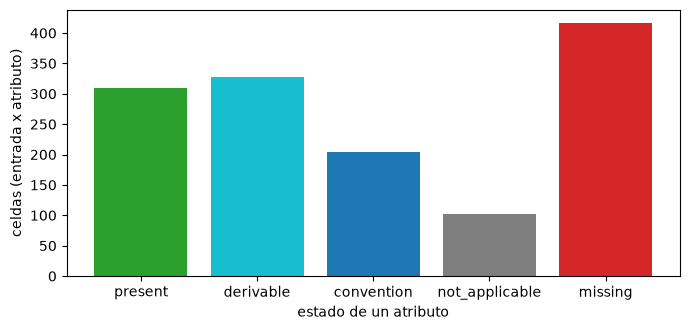

In [3]:
# Contar el estado de los 40 atributos de las 34 entradas
statuses = ("present", "derivable", "convention", "not_applicable", "missing")
totals = Counter()
for counts in inventory["completeness"]["attributes"].values():
    totals.update(counts)
never = [a for a, c in inventory["completeness"]["attributes"].items() if c["missing"] == len(entries)]
print("celdas de atributos:", sum(totals.values()), "|", {s: totals[s] for s in statuses})
print("atributos ausentes en toda entrada:", len(never), "of 40")
fig, ax = plt.subplots(figsize=(7, 3.4))
ax.bar(statuses, [totals[s] for s in statuses], color=["tab:green", "tab:cyan", "tab:blue", "tab:gray", "tab:red"])
ax.set_xlabel("estado de un atributo")
ax.set_ylabel("celdas (entrada x atributo)")
fig.tight_layout()
plt.show()

Las 34 entradas tienen 1.360 celdas de atributos: 310 presentes, 327 derivables, 204 convenciones, 102 no aplicables y 417 ausentes. Diez de los 40 atributos faltan en todas las entradas. La figura es la parte honesta del inventario: casi una celda de cada tres es una brecha que el producto registra y no rellena, porque ningún documento dice si se usan datos alternativos ni cuáles son las limitaciones conocidas. El registro de modelos tiene 25 estudios nombrados y 564 filas de paridad, así que la entrada C22 se apoya en los mismos tamaños y potencias que miden los notebooks de este tema; la figura no dice qué brechas importan, solo cuántas hay.

### Paso 2: el nivel de cada entrada

La celda siguiente recalcula el nivel de las 34 entradas con `tiering.materiality`, `tiering.complexity` y `tiering.matrix_tier` a partir de los puntajes de cada `tier_block`, los compara con los niveles confirmados y dibuja cuántas entradas caen en cada celda de la matriz, con el nivel de cada celda escrito en ella.

niveles iguales a los confirmados: True
entradas en los niveles 1 a 4: (18, 15, 0, 1)


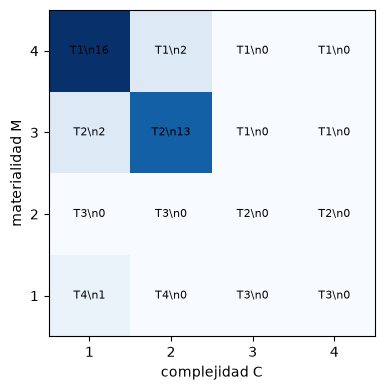

In [4]:
# Recalcular el nivel de cada entrada con el motor y ubicarlo en la matriz
from riskvalidation.governance import tiering

grid = np.zeros((4, 4), int)
tiers, inputs = [], []
for entry in entries:
    block = entry["tier_block"]
    band = block["materiality"]["exposure"]["band"]
    graded = block["materiality"]["regulatory_use"]["graded"]
    m = tiering.materiality(band, graded, block["materiality"]["decision_criticality"]["score"])
    c = tiering.complexity([f["score"] for f in block["complexity"]["factors"] if f["score"] is not None])
    tiers.append(tiering.matrix_tier(m, c))
    share = block["materiality"]["exposure"]["share"]
    inputs.append((share, graded, block["materiality"]["decision_criticality"]["score"], c))
    grid[m - 1, c - 1] += 1
print("niveles iguales a los confirmados:", all(t == e["tier_block"]["tier"] for t, e in zip(tiers, entries)))
print("entradas en los niveles 1 a 4:", tiering.tier_counts(tiers))
fig, ax = plt.subplots(figsize=(5, 4))
ax.imshow(grid, origin="lower", cmap="Blues")
for m in range(4):
    for c in range(4):
        ax.text(c, m, f"T{tiering.matrix_tier(m + 1, c + 1)}\\n{grid[m, c]}", ha="center", va="center", fontsize=8)
ax.set_xticks(range(4), ["1", "2", "3", "4"])
ax.set_yticks(range(4), ["1", "2", "3", "4"])
ax.set_xlabel("complejidad C")
ax.set_ylabel("materialidad M")
fig.tight_layout()
plt.show()

Los 34 niveles recalculados son iguales a los confirmados, y las entradas caen en el nivel 1 (18 entradas), el nivel 2 (15), el nivel 3 (ninguna) y el nivel 4 (1). Ninguna entrada cae en una celda de la matriz que dé nivel 3, y la figura muestra dónde están las 34 entradas, de modo que un lector ve qué puntaje tendría que cambiar para mover una.

### Paso 3: el mismo inventario bajo las cuatro lecturas

La rúbrica deja abiertas dos decisiones: si el uso regulatorio es graduado o literal, y si la complejidad es el promedio o el máximo de sus factores. El `tier_sensitivity` del motor devuelve el nivel bajo las cuatro combinaciones, A (literal, promedio), B (graduado, promedio, la lectura adoptada), C (literal, máximo) y D (graduado, máximo). La celda siguiente las lee de cada entrada y cuenta los niveles bajo cada lectura.

A (33, 0, 0, 1)
B (18, 15, 0, 1)
C (33, 0, 0, 1)
D (31, 2, 0, 1)


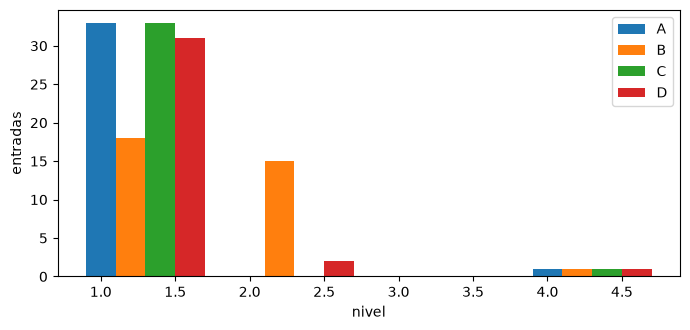

In [5]:
# Leer el nivel de cada entrada bajo las cuatro lecturas de la rúbrica
readings = {"A": [], "B": [], "C": [], "D": []}
for entry in entries:
    for item in entry["tier_block"]["tier_sensitivity"]:
        readings[item["reading"]].append(item["tier"])
width = 0.2
fig, ax = plt.subplots(figsize=(7, 3.4))
for index, (name, values) in enumerate(readings.items()):
    counts = tiering.tier_counts(values)
    ax.bar(np.arange(1, 5) + index * width, counts, width, label=name)
    print(name, counts)
ax.set_xlabel("nivel")
ax.set_ylabel("entradas")
ax.legend()
fig.tight_layout()
plt.show()

La lectura B, la adoptada, pone 18 entradas en el nivel 1 y 15 en el nivel 2. Las lecturas A y C ponen 33 en el nivel 1 y ninguna en el 2, y la D pone 31 y 2. Una entrada, el caso del generador, es nivel 4 bajo las cuatro. La elección de la lectura mueve entonces 15 modelos del nivel 2 al nivel 1 y con ello su ciclo de revisión y sus plazos; la figura muestra que el nivel no es un hecho sino una lectura, y que el producto muestra las otras tres junto a la adoptada.

### Paso 4: plazos y escala de severidad

El plazo de un hallazgo son `deadline_days(severity, tier)` días desde `raised`, su fecha de vencimiento `due_date(raised, days)` y su nivel del BCE `severity_to_ecb`. La celda recalcula ambos para cada fila del registro, cuenta las filas que difieren de las confirmadas y dibuja la tabla de plazos.

filas con plazo o vencimiento distintos: 0 de 745
severidad a nivel del BCE: {'S1': 'F4', 'S2': 'F3', 'S3': 'F2', 'S4': 'F1'}


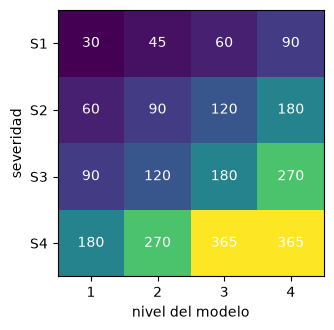

In [6]:
# Recalcular el plazo y la fecha de vencimiento de cada hallazgo y dibujar la tabla de plazos
from riskvalidation.governance import findings as gf

mismatch = 0
for row in rows:
    days = gf.deadline_days(row["severity"], row["tier"])
    due = gf.due_date(date.fromisoformat(row["raised"]), days)
    mismatch += (days != row["deadline_days"]) or (due.isoformat() != row["due"])
print("filas con plazo o vencimiento distintos:", mismatch, "de", len(rows))
print("severidad a nivel del BCE:", {s: gf.severity_to_ecb(s) for s in ("S1", "S2", "S3", "S4")})
table = np.array([[gf.deadline_days(s, t) for t in range(1, 5)] for s in ("S1", "S2", "S3", "S4")])
fig, ax = plt.subplots(figsize=(5, 3.4))
ax.imshow(table, cmap="viridis")
for i in range(4):
    for j in range(4):
        ax.text(j, i, table[i, j], ha="center", va="center", color="white")
ax.set_xticks(range(4), ["1", "2", "3", "4"])
ax.set_yticks(range(4), ["S1", "S2", "S3", "S4"])
ax.set_xlabel("nivel del modelo")
ax.set_ylabel("severidad")
fig.tight_layout()
plt.show()

Ninguna fila del registro difiere: los plazos y vencimientos confirmados son los del motor. La tabla es monótona, como exige el invariante del motor: un hallazgo crítico en un modelo de nivel 1 debe cerrarse en 30 días, uno menor en un modelo de nivel 4 en 365, y los números son una convención (ítem 30 del dosier), no una norma. La correspondencia de S1, S2, S3 y S4 con F4, F3, F2 y F1 conserva la dirección del producto, con S1 el más severo, y lee la escala del BCE.

### Paso 5: la opinión sobre cada modelo

La opinión toma solo los hallazgos abiertos (abiertos, con plan de acción, en curso, enviados a cierre o vencidos); un hallazgo aceptado o cerrado no cuenta. La celda arma la lista de pares (severidad, proporción de RWEA) de cada entrada, aplica `opinion_level` e imprime el número de entradas por nivel y la recomendación de cada nivel.

In [7]:
# Dar a cada modelo la opinión que producen sus hallazgos abiertos
from riskvalidation.governance import opinion

OPEN = {"open", "action_plan_agreed", "in_progress", "submitted_for_closure", "overdue"}
by_entry = {}
for row in rows:
    if row["status"] in OPEN:
        by_entry.setdefault(row["entry_key"], []).append((row["severity"], row["rwea_share"]))
levels = {key: opinion.opinion_level(items) for key, items in by_entry.items()}
print("entradas por nivel de opinión:", dict(sorted(Counter(levels.values()).items())))
print("entradas sin hallazgo abierto:", len(entries) - len(by_entry))
for level in (1, 2, 3, 4):
    print(level, opinion.recommendation(level)[0])

entradas por nivel de opinión: {3: 32, 4: 2}
entradas sin hallazgo abierto: 0
1 approve
2 approve with conditions
3 remediate before use
4 remediate before use


Treinta y dos entradas reciben el nivel 3 y dos el nivel 4, y toda entrada tiene al menos un hallazgo abierto. La recomendación de los niveles 3 y 4 es la misma, remediar antes de usar, y el motor la rotula como la salida de la regla sobre la evidencia: Contraste no aprueba ningún modelo. Un validador debe leer la figura como que el inventario confirmado no contiene ningún modelo que la regla pasaría sin condiciones, lo que se sigue de los hallazgos que las pruebas levantan sobre datos generados, no de un juicio sobre los modelos.

### Paso 6: las métricas de apetito y los valores de referencia del contrato

Siete métricas resumen el registro frente a umbrales. La celda las recalcula con `appetite_metrics` desde las entradas y las filas, compara cada una con el valor y la luz confirmados, cuenta los hallazgos S1 o S2 abiertos del propio inventario que el registro no guarda, y corre el motor sobre el fixture de cuatro entradas, cuyas luces declara el contrato como verde, rojo, ámbar, verde, rojo, verde, rojo.

In [8]:
# Recalcular las siete métricas de apetito y el fixture del contrato
from riskvalidation.governance import appetite as ga

today = date.fromisoformat(appetite["as_of"])
live = ga.appetite_metrics(entries, rows, today)
fixture_rows = read(ROOT / "docs" / "contracts" / "fixtures" / "governance" / "findings-fixture.json")["rows"]
golden = ga.appetite_metrics(fixture["entries"], fixture_rows, date(2026, 12, 31))
for item, kept in zip(live, appetite["metrics"]):
    print(f"{item['id']:26s} {item['value']!s:.8s} {item['light']:6s}", end=" ")
    print(f"| confirmado {kept['value']!s:.8s} {kept['light']}")
extra = sum(g["severity"] in ("S1", "S2") and g["status"] == "open" for g in inventory["governance_findings"])
print("hallazgos S1 o S2 abiertos del propio inventario:", extra, "| registro más esos:", live[1]["value"] + extra)
print("semáforos del fixture:", [item["light"] for item in golden])

tier1-validated-on-time    1.0 green  | confirmado 1.0 green
open-high-severity         144 red    | confirmado 145 red
overdue-remediation        0 green  | confirmado 0 green
entries-under-exception    0 green  | confirmado 0 green
entries-in-breach          32 red    | confirmado 32 red
pma-magnitude              0.003321 green  | confirmado 0.003321 green
owner-and-complete-record  0.0 red    | confirmado 0.0 red
hallazgos S1 o S2 abiertos del propio inventario: 1 | registro más esos: 145
semáforos del fixture: ['green', 'red', 'amber', 'green', 'red', 'green', 'red']


Seis métricas se reproducen exactamente. El conteo de hallazgos abiertos de alta severidad es 144 aquí y 145 en el archivo confirmado, ambos en rojo: el inventario lleva dos hallazgos propios, y uno está abierto con severidad S2, que el registro no guarda; 144 más 1 es el 145 confirmado. Sobre el fixture el motor devuelve las luces que declara el contrato, en orden verde, rojo, ámbar, verde, rojo, verde y rojo, que es la comprobación del motor contra su contrato. Cuatro de las siete luces son verdes y tres rojas; la métrica de dueño y registro completo es 0,0 y roja porque toda entrada tiene atributos ausentes, como mostró el paso 1.

### Sensibilidad: dónde cambia o se rompe el método

Dos números deciden los veredictos anteriores y ninguno está medido: la proporción de RWEA en que un hallazgo sube de nivel y los cortes de la banda de exposición. La primera celda barre la proporción de 0 a 15 % para hallazgos de severidad S1, S3 y S4 y escribe dónde cambia el nivel; la segunda barre el corte superior de la banda de 15 % a 50 % y cuenta los niveles, con los otros cortes en 10 % y 2 %.

S1 el nivel cambia en las proporciones []
S3 el nivel cambia en las proporciones [0.05, 0.1]
S4 el nivel cambia en las proporciones [0.05, 0.1]


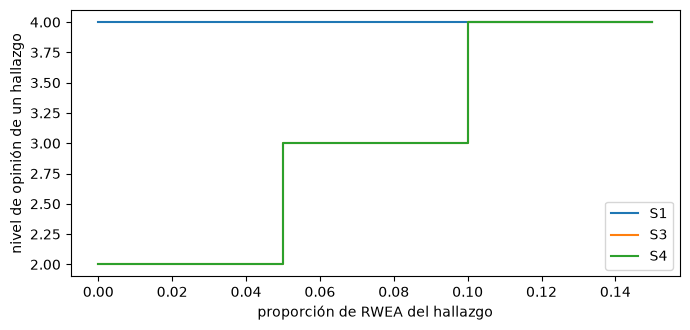

corte superior 0.15 {1: 28, 2: 5, 4: 1}
corte superior 0.2 {1: 26, 2: 7, 4: 1}
corte superior 0.25 {1: 18, 2: 15, 4: 1}
corte superior 0.35 {1: 14, 2: 19, 4: 1}
corte superior 0.5 {1: 14, 2: 19, 4: 1}


In [9]:
# Barrer la proporción de RWEA de un hallazgo y el corte superior de la banda de exposición
shares = np.linspace(0.0, 0.15, 301)
fig, ax = plt.subplots(figsize=(7, 3.4))
for severity in ("S1", "S3", "S4"):
    steps = [opinion.finding_level(severity, share) for share in shares]
    ax.step(shares, steps, where="post", label=severity)
    jumps = [round(float(shares[i]), 4) for i in range(1, len(steps)) if steps[i] != steps[i - 1]]
    print(severity, "el nivel cambia en las proporciones", jumps)
ax.set_xlabel("proporción de RWEA del hallazgo")
ax.set_ylabel("nivel de opinión de un hallazgo")
ax.legend()
fig.tight_layout()
plt.show()
cuts_grid = (0.15, 0.20, 0.25, 0.35, 0.50)
for top in cuts_grid:
    counts = Counter()
    for share, graded, criticality, c in inputs:
        band = tiering.exposure_band(share, (top, 0.10, 0.02))
        counts[tiering.matrix_tier(tiering.materiality(band, graded, criticality), c)] += 1
    print("corte superior", top, dict(sorted(counts.items())))

Un hallazgo crítico es nivel 4 en cualquier proporción, así que ninguna lo cambia. Un hallazgo mayor o menor (S3, S4) cambia en exactamente dos puntos, 5 % y 10 %, los niveles 3 y 4 de la instrucción del BCE, y por eso un ancla pequeña puede subir un hallazgo menor a un nivel que bloquea el uso. Los conteos de niveles se mueven con el corte superior: con 15 % hay 28 entradas en el nivel 1 y 5 en el nivel 2, con 20 % 26 y 7, con 25 % (el corte del producto) 18 y 15, y con 35 % 14 y 19, y los conteos no cambian entre 35 % y 50 %. El régimen donde el veredicto se rompe es una cartera cuyas proporciones de exposición quedan cerca de un corte: pasar el corte de 25 % a 20 % mueve ocho modelos entre niveles, y los documentos confirmados registran esa elección como una convención y no la ponen a prueba.

### Úsalo con tus propios datos

La cadena necesita, para un modelo, la proporción del saldo que cubre, el grado de uso regulatorio (1 a 4), el puntaje de criticidad de la decisión (1 a 4), los puntajes de los factores de complejidad (1 a 4 cada uno) y, para cada hallazgo, su severidad, la fecha en que se levantó y, cuando el ancla es una proporción de RWEA, esa proporción. `tiering.exposure_band`, `materiality`, `complexity` y `matrix_tier` dan el nivel; `apply_override` recibe el nivel y un ajuste opcional (nuevo nivel, justificación, aprobador) y rechaza un ajuste con justificación o aprobador vacíos; `findings.deadline_days`, `due_date` y `is_overdue` dan los plazos; `opinion.opinion_level` y `recommendation` dan la opinión; `appetite.light` convierte un conteo en un color. La celda siguiente corre la cadena sobre un modelo ilustrativo con 8 % del saldo, un uso graduado de 3, una criticidad de 2, seis puntajes de complejidad y dos hallazgos levantados el 1 de septiembre de 2026, leídos el 31 de diciembre.

In [10]:
# Correr la cadena completa sobre un modelo propio: nivel, plazos, opinión, semáforo
share, graded_use, criticality = 0.08, 3, 2
scores = [3, 2, 2, 1, 1, 1]
m = tiering.materiality(tiering.exposure_band(share), graded_use, criticality)
c = tiering.complexity(scores)
tier = tiering.matrix_tier(m, c)
final = tiering.apply_override(tier, (1, "el modelo alimenta la prueba de estrés", "Gerente de Riesgos"))
print("M", m, "| C", c, "| nivel:", tier, "| tras el ajuste:", final)
raised, as_of = date(2026, 9, 1), date(2026, 12, 31)
items = [("S2", 0.06), ("S3", None)]
for severity, share_rwea in items:
    days = gf.deadline_days(severity, final)
    due = gf.due_date(raised, days)
    print(severity, "días de plazo:", days, "| vence:", due, "| vencido:", gf.is_overdue("open", due, as_of))
level = opinion.opinion_level(items)
print("nivel de opinión:", level, "|", opinion.recommendation(level)[0])
print("semáforo de dos vencidos frente a 0 y 3:", ga.light(2, "lower-is-better", 0, 3))

M 3 | C 2 | nivel: 2 | tras el ajuste: 1
S2 días de plazo: 60 | vence: 2026-10-31 | vencido: True
S3 días de plazo: 90 | vence: 2026-11-30 | vencido: True
nivel de opinión: 3 | remediate before use
semáforo de dos vencidos frente a 0 y 3: amber


El modelo tiene materialidad 3 y complejidad 2, así que es nivel 2, y el ajuste con justificación y aprobador declarados lo lleva al nivel 1. Su hallazgo S2 tiene 60 días y vence el 31 de octubre de 2026, su hallazgo S3 90 días y el 30 de noviembre, y ambos están vencidos al 31 de diciembre. La opinión es nivel 3, remediar antes de usar, impulsada por el hallazgo S2 con 6 % de RWEA, y dos hallazgos vencidos frente a umbrales de 0 y 3 dan ámbar. Al adaptar la celda, revisa que el ajuste lleve una justificación y un aprobador reales, pues uno vacío levanta un error por diseño; que los hallazgos que pasas a la opinión sean solo los abiertos; y que el estado que pasas a `is_overdue` sea el del flujo de trabajo y no el del producto, porque un hallazgo con riesgo aceptado nunca está vencido.

## Resultados

**Respuesta:** Los resultados se convierten en un nivel mediante una matriz de materialidad y complejidad, en un plazo mediante una tabla de severidad y nivel, en una opinión mediante el nivel más alto entre los hallazgos abiertos y en una luz mediante siete métricas contadas, y el motor reproduce todos los valores confirmados: los 34 niveles, todos los plazos y vencimientos del registro y seis de los siete valores de apetito, y el séptimo difiere por el hallazgo S2 abierto del propio inventario (144 frente a 145). Los veredictos descansan más en convenciones que en evidencia: leer la rúbrica de otra manera mueve 15 de 34 modelos del nivel 2 al nivel 1, y pasar el corte superior de la banda de exposición de 25 % a 20 % mueve ocho.

- **El inventario es honesto sobre sus brechas.** Faltan 417 de 1.360 celdas de atributos, y diez atributos faltan en todas las entradas.
- **La opinión es uniforme aquí.** 32 entradas están en el nivel 3 y 2 en el nivel 4, ninguna en el nivel 1 o 2, porque todo modelo tiene hallazgos abiertos.
- **El motor cumple su contrato.** El fixture devuelve las luces verde, rojo, ámbar, verde, rojo, verde y rojo.

Lo que este notebook no hace es juzgar un modelo: la capa aplica reglas declaradas a los resultados y lo dice en cada rótulo.

## Resumen

- La capa de gobierno convierte resultados de pruebas en un nivel, un plazo, una opinión y una luz de apetito con funciones de `riskvalidation.governance`, que un notebook llama y nunca reimplementa.
- Los 34 niveles, todos los plazos y vencimientos del registro y seis de siete métricas de apetito se recalculan exactamente; la séptima difiere en un hallazgo que guarda el propio inventario.
- El nivel es una lectura: cuatro lecturas de la rúbrica dan 18, 33, 33 y 31 entradas en el nivel 1.
- Un hallazgo sube al nivel 3 con 5 % de RWEA y al nivel 4 con 10 %, sea cual sea su severidad, salvo que uno crítico es nivel 4 en cualquier proporción.
- Para usarlo en un modelo propio, entrega la proporción, los dos grados, los puntajes de factores y los hallazgos, y llama a las funciones de la última sección.

**Qué probar después.** Agrega un segundo modelo a la última celda, con otro nivel, y compara los plazos de sus hallazgos; luego lee el notebook 04 del tema 13 sobre las pruebas que alimentan el registro.

## Referencias

- Board of Governors of the Federal Reserve System (2011), SR 11-7: Guidance on model risk management. https://www.federalreserve.gov/supervisionreg/srletters/sr1107.htm
- BCE (2019), Instructions for reporting the validation results of internal models: IRB Pillar I models for credit risk, sección 2.4.2 (la escala de cuatro niveles y las proporciones de RWEA). https://www.bankingsupervision.europa.eu/activities/internal_models/shared/pdf/instructions_validation_reporting_credit_risk.en.pdf
- Prudential Regulation Authority (2023), SS1/23: Model risk management principles for banks. https://www.bankofengland.co.uk/prudential-regulation/publication/2023/may/model-risk-management-principles-for-banks-ss
- Este repositorio: el contrato de gobierno del motor, `docs/contracts/engine/governance-api.md`. https://github.com/fsantibanezleal/CAOS_Contraste/blob/main/docs/contracts/engine/governance-api.md
- Este repositorio: `docs/contracts/catalog.md`, los contratos `c22-models`, `governance-inventory`, `governance-findings`, `governance-report` y `governance-appetite`.